**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**17 | Fixed-Optimiser-Step Training-Data Comparison**

![Stage 17 scientific workflow](../../images/17_workflow.svg)

**Objective:** Compare 500- and 1,000-window-per-participant training cohorts for a weighted CNN under the same 400-optimiser-update budget.

**Dataset:** The nested HARTH v2.0 Development windows from Notebook 16, with 29 participants, three subject-disjoint folds and reserved Test participants S023 and S032 excluded.

**Notebook Scope:** Train both CNN conditions for 400 updates per fold, inspect predetermined checkpoints and compare final-step results on identical base-500 Validation windows. Equal update counts do not imply equal sample exposures or processing time.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


**01. Imports and Reusable Scientific Components**

In [1]:
# ============== 01. Imports and Reusable Scientific Components ===============

# ----------------------------- Standard Library ------------------------------
import sys
from pathlib import Path

# ------------------ Scientific Computing and Visualisation -------------------
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

# ------------------------- Deep Learning and Display -------------------------
import torch

from IPython.display import display

# ------------------- Grouped Validation and Model Metrics --------------------
from sklearn.model_selection import GroupKFold

from sklearn.metrics import f1_score, balanced_accuracy_score

# ------------------------- Repository Configuration --------------------------
root = Path.cwd().resolve()

while not (root / "python_modules/core/data_loading.py").is_file():
    if root.parent == root: raise RuntimeError("Open notebook within repository.")
    root = root.parent

# ----------------------- Shared and HARTH Module Paths -----------------------
sys.path.insert(0, str(root / "python_modules"))

sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ------------------ HARTH Data and CNN Evaluation Utilities ------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_nested_window_cohort

from core.temporal_cnn import train_temporal_cnn_fixed_steps

from core.ml_baselines import evaluate_predictions_by_subject, classification_class_report

from core.group_cross_validation import compare_models_by_subject

# ------------------------- PyTorch Environment Check -------------------------
print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())


PyTorch: 2.12.1+cpu CUDA: False


**02. Recreate the Nested Development Source Cohort**

Reuse the 14,201 base-500 windows and the 28,201-window expanded cohort from Notebook 16. The base windows remain a subset of the expanded data; both conditions retain the same documented activity task and exclude reserved Test recordings.

In [2]:
# ============= 02. Recreate the Nested Development Source Cohort =============

# -------------- Development Cohort and Original Test Exclusion ---------------
RESERVED_TEST = {"S023", "S032"}

DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------------------- Documented Activity Task --------------------------
TASK_CLASSES = tuple(range(1, 9))

# --------------------- Strictly Nested Six-Axis Windows ----------------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS, data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, base_cap=500, expanded_cap=1000,
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------------- Base Window Indices and Source Labels -------------------
base_mask = metadata["in_base_500"].to_numpy(dtype=bool)

base_rows = np.flatnonzero(base_mask)

labels = metadata["label"].to_numpy()

subjects = metadata["subject_id"].to_numpy()

# ------------------- Cohort Integrity and Sampling Summary -------------------
assert len(base_rows) == 14201 and len(X) == 28201

assert not (set(subjects) & RESERVED_TEST)

print("Base / expanded windows:", len(base_rows), len(X))

display(overview)


Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Base / expanded windows: 14201 28201


,subject_id,eligible_windows,base_windows,expanded_windows,new_training_windows
0,S006,6708,500,1000,500
1,S008,7392,500,1000,500
2,S009,201,201,201,0
3,S010,6077,500,1000,500
4,S012,7309,500,1000,500
5,S013,6402,500,1000,500
6,S014,6299,500,1000,500
7,S015,7453,500,1000,500
8,S016,6272,500,1000,500
9,S017,6678,500,1000,500


**03. Keep Participant-Disjoint Folds Fixed**

Partition base-500 windows into three outer folds holding out 10, 10 and nine complete participants. Each condition uses the same Validation rows. Additional 1,000-cap windows are available only from fold Train participants.

In [3]:
# ================= 03. Keep Participant-Disjoint Folds Fixed =================

# ------------------- Participant-Disjoint Fold Definition --------------------
FOLDS = 3

group_folds = list(GroupKFold(n_splits=FOLDS).split(
    np.zeros(len(base_rows)), labels[base_rows], groups=subjects[base_rows]
))

# -------------------- Fold Design and Subject Separation ---------------------
fold_design = []

for fold, (tr, va) in enumerate(group_folds, start=1):
    train_people = set(subjects[base_rows[tr]])
    validation_people = set(subjects[base_rows[va]])
    assert not (train_people & validation_people)
    expanded_train = np.flatnonzero(np.isin(subjects, list(train_people)))
    assert np.isin(base_rows[tr], expanded_train).all()
    fold_design.append({
        "fold": fold, "train_people": len(train_people),
        "validation_people": len(validation_people),
        "train_500": len(tr), "train_1000": len(expanded_train),
        "fixed_validation": len(va),
    })

# ----------------------- Fixed Validation Fold Summary -----------------------
display(pd.DataFrame(fold_design))


,fold,train_people,validation_people,train_500,train_1000,fixed_validation
0,1,19,10,9201,18201,5000
1,2,19,10,9500,19000,4701
2,3,20,9,9701,19201,4500


**04. Train Weighted CNNs for 400 Optimiser Updates**

Start both models with the specified seed, optimiser settings and batch size. Evaluate at the predefined steps 100, 200, 300 and 400. The completed matched comparison uses step 400 for both training conditions, not the best intermediate Validation checkpoint. This controls the number of optimiser updates, but not the number of times individual source windows are encountered.

In [4]:
# ============= 04. Train Weighted CNNs for 400 Optimiser Updates =============

# ------------------- Fixed Training and Evaluation Budget --------------------
MAX_STEPS = 400

EVAL_EVERY = 100

# ----------------- PyTorch Device and Evaluation Containers ------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

fold_records, people_frames, class_frames, histories = [], [], [], []

# ----------------------- Matched Weighted CNN Training -----------------------
for fold, (train_local, validation_local) in enumerate(group_folds, start=1):
    train_rows_500 = base_rows[train_local]
    val_rows = base_rows[validation_local]
    train_people = set(subjects[train_rows_500])
    train_rows_1000 = np.flatnonzero(np.isin(subjects, list(train_people)))
    y_val = labels[val_rows]
    for name, selected_train in [
        ("Weighted CNN 500", train_rows_500),
        ("Weighted CNN 1000", train_rows_1000),
    ]:
        print(f"Fold {fold}/{FOLDS} | {name} | {len(selected_train)} Train windows")
        model, history, predicted, statistics = train_temporal_cnn_fixed_steps(
            X_train=X[selected_train], y_train=labels[selected_train],
            X_validation=X[val_rows], y_validation=y_val,
            classes=TASK_CLASSES, max_steps=MAX_STEPS,
            eval_every=EVAL_EVERY, batch_size=128, learning_rate=1e-3,
            seed=42, device=DEVICE, class_weighting="inverse_sqrt",
        )
        fold_records.append({
            "fold":fold, "model":name, "train_windows":len(selected_train),
            "validation_windows":len(val_rows),
            "macro_f1":f1_score(y_val,predicted,labels=TASK_CLASSES,
                                average="macro",zero_division=0),
            "balanced_accuracy":balanced_accuracy_score(y_val,predicted),
        })
        frame = evaluate_predictions_by_subject(
            y_val,predicted,subjects[val_rows],TASK_CLASSES,name
        )
        frame.insert(0,"fold",fold)
        people_frames.append(frame)
        report=classification_class_report(
            y_val,predicted,classes=TASK_CLASSES,
            class_names=[ACTIVITY_NAMES[code] for code in TASK_CLASSES],
        )
        report["fold"],report["model"]=fold,name
        class_frames.append(report)
        history["fold"],history["model"]=fold,name
        histories.append(history)

# ------------------ Fold, Participant and Activity Results -------------------
fold_results=pd.DataFrame(fold_records)

subject_results=pd.concat(people_frames,ignore_index=True)

class_results=pd.concat(class_frames,ignore_index=True)

# ---------------- Optimisation History and Validation Summary ----------------
history_table=pd.concat(histories,ignore_index=True)

display(fold_results.round(4))


Fold 1/3 | Weighted CNN 500 | 9201 Train windows
Step 100/400 | loss=0.8975 | Validation Macro F1=0.5829
Step 200/400 | loss=0.4791 | Validation Macro F1=0.7315
Step 300/400 | loss=0.3274 | Validation Macro F1=0.7661
Step 400/400 | loss=0.2508 | Validation Macro F1=0.7448
Fold 1/3 | Weighted CNN 1000 | 18201 Train windows
Step 100/400 | loss=0.8877 | Validation Macro F1=0.5860
Step 200/400 | loss=0.4701 | Validation Macro F1=0.7490
Step 300/400 | loss=0.3450 | Validation Macro F1=0.7403
Step 400/400 | loss=0.2571 | Validation Macro F1=0.7588
Fold 2/3 | Weighted CNN 500 | 9500 Train windows
Step 100/400 | loss=0.8796 | Validation Macro F1=0.5864
Step 200/400 | loss=0.4411 | Validation Macro F1=0.6882
Step 300/400 | loss=0.3448 | Validation Macro F1=0.7817
Step 400/400 | loss=0.2621 | Validation Macro F1=0.7862
Fold 2/3 | Weighted CNN 1000 | 19000 Train windows
Step 100/400 | loss=0.8686 | Validation Macro F1=0.5882
Step 200/400 | loss=0.4489 | Validation Macro F1=0.6820
Step 300/400 | l

,fold,model,train_windows,validation_windows,macro_f1,balanced_accuracy
0,1,Weighted CNN 500,9201,5000,0.7448,0.8154
1,1,Weighted CNN 1000,18201,5000,0.7588,0.8153
2,2,Weighted CNN 500,9500,4701,0.7862,0.8139
3,2,Weighted CNN 1000,19000,4701,0.7976,0.7731
4,3,Weighted CNN 500,9701,4500,0.7928,0.7782
5,3,Weighted CNN 1000,19201,4500,0.8218,0.8058


**05. Compare Final-Step Macro F1 Across Folds**

At step 400, recorded three-fold mean Macro F1 was 0.7746 for weighted CNN 500 and 0.7927 for weighted CNN 1000. These are Development estimates from matched held-out folds, not independent Test performance.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,Weighted CNN 1000,0.7927,0.0318,0.7980
1,Weighted CNN 500,0.7746,0.0260,0.8025


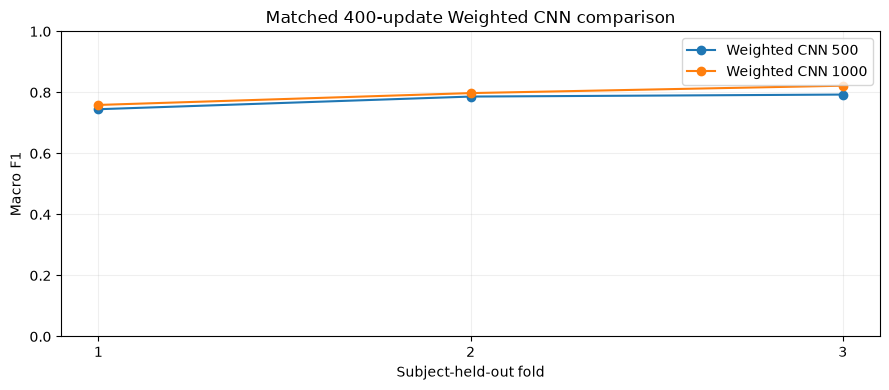

In [5]:
# =============== 05. Compare Final-Step Macro F1 Across Folds ================

# ------------------------- Three-Fold Model Summary --------------------------
summary=fold_results.groupby("model",as_index=False).agg(
    macro_f1_mean=("macro_f1","mean"),
    macro_f1_sd=("macro_f1","std"),
    balanced_accuracy_mean=("balanced_accuracy","mean"),
)

display(summary.round(4))

# --------------------- Held-Out Fold Macro F1 Comparison ---------------------
fig,ax=plt.subplots(figsize=(9,4))

for name,group in fold_results.groupby("model",sort=False):
    ax.plot(group["fold"],group["macro_f1"],marker="o",label=name)

ax.set(title="Matched 400-update Weighted CNN comparison",
       xlabel="Subject-held-out fold",ylabel="Macro F1",
       xticks=[1,2,3],ylim=(0,1))
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


**06. Inspect Fixed-Checkpoint Validation Trends**

Show Validation scores at the four predetermined checkpoints. Intermediate values describe the training trajectory; the reported comparison uses step 400 rather than the highest observed earlier score.

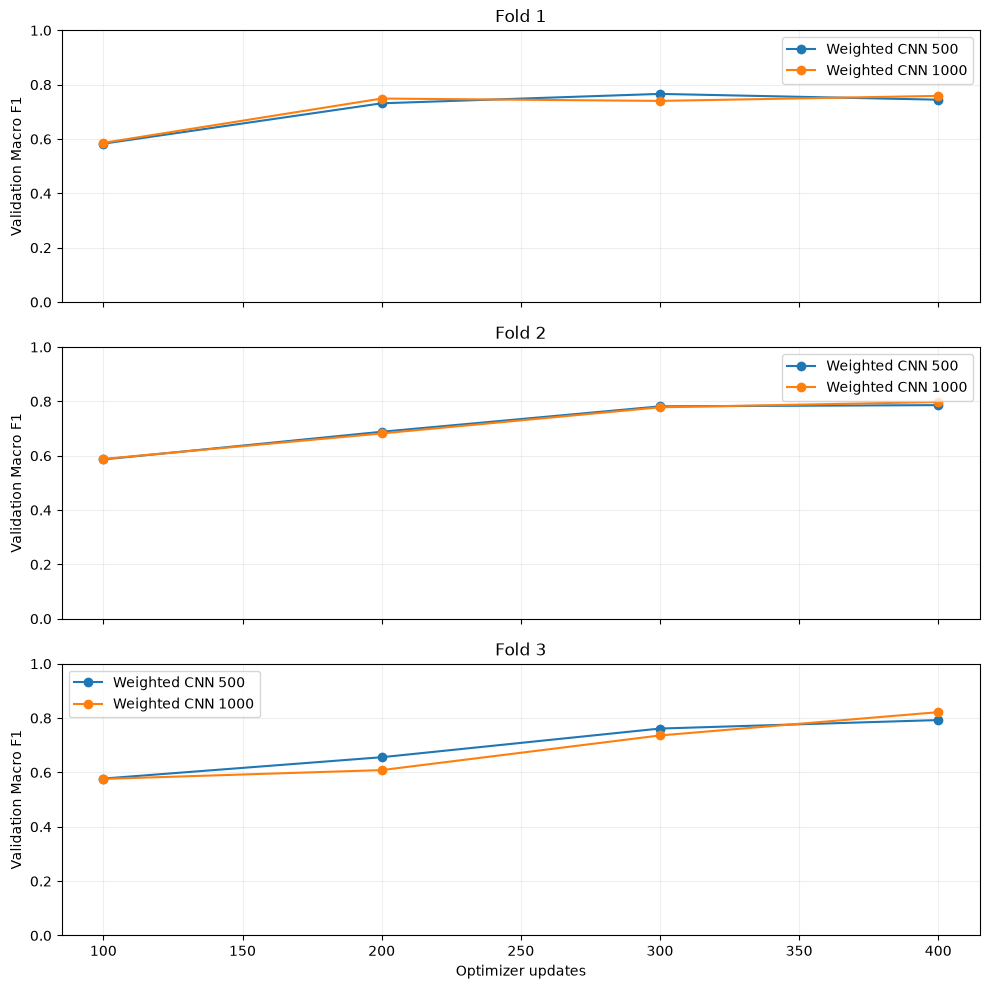

In [6]:
# ============== 06. Inspect Fixed-Checkpoint Validation Trends ===============

# --------------------- Matched-Update Validation Curves ----------------------
fig,axes=plt.subplots(3,1,figsize=(10,10),sharex=True)

for fold,ax in zip(range(1,FOLDS+1),axes):
    for name,group in history_table.loc[
        history_table["fold"]==fold
    ].groupby("model",sort=False):
        ax.plot(group["step"],group["validation_macro_f1"],
                marker="o",label=name)
    ax.set(title=f"Fold {fold}",ylabel="Validation Macro F1",ylim=(0,1))
    ax.grid(alpha=0.2)
    ax.legend()

axes[-1].set_xlabel("Optimizer updates")
fig.tight_layout()
plt.show()


**07. Inspect Participant and Minority-Class Differences**

Compare fixed-task scores on the same held-out participants, with particular attention to Shuffling and stair activities. The larger training condition scored higher for 18 participants and lower for 11.

,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN 1000,Weighted CNN 500,macro_f1_fixed_task,29,0.018,0.0018,18,11,0


,subject_id,score_a,score_b,difference_a_minus_b
0,S006,0.6614,0.6860,-0.0246
1,S008,0.3683,0.3561,0.0122
2,S009,0.3485,0.3467,0.0018
3,S010,0.5088,0.6317,-0.1229
4,S012,0.8399,0.7733,0.0667
5,S013,0.6839,0.7401,-0.0563
6,S014,0.7774,0.7996,-0.0222
7,S015,0.7046,0.7412,-0.0365
8,S016,0.7826,0.6119,0.1707
9,S017,0.5698,0.6449,-0.0751


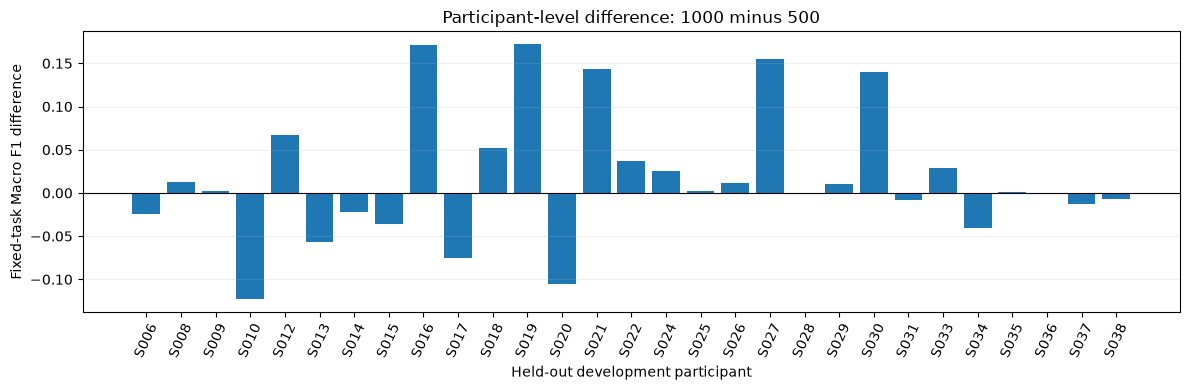

,fold,model,class,support,precision,recall,f1
2,1,Weighted CNN 500,Shuffling,51,0.1111,0.1373,0.1228
3,1,Weighted CNN 500,Stairs ascending,57,0.2781,0.7368,0.4038
4,1,Weighted CNN 500,Stairs descending,46,0.4659,0.8913,0.6119
10,1,Weighted CNN 1000,Shuffling,51,0.1795,0.1373,0.1556
11,1,Weighted CNN 1000,Stairs ascending,57,0.2710,0.7368,0.3962
12,1,Weighted CNN 1000,Stairs descending,46,0.5758,0.8261,0.6786
18,2,Weighted CNN 500,Shuffling,66,0.3871,0.1818,0.2474
19,2,Weighted CNN 500,Stairs ascending,63,0.4240,0.8413,0.5638
20,2,Weighted CNN 500,Stairs descending,52,0.6250,0.6731,0.6481
26,2,Weighted CNN 1000,Shuffling,66,0.2791,0.1818,0.2202


In [7]:
# ========== 07. Inspect Participant and Minority-Class Differences ===========

# ------------------------ Paired Participant Macro F1 ------------------------
paired,paired_summary=compare_models_by_subject(
    subject_results,"Weighted CNN 1000","Weighted CNN 500",
    score_column="macro_f1_fixed_task",  # Compare the same eight classes per participant.
)

display(pd.DataFrame([paired_summary]).round(4))

display(paired.round(4))

# -------------------- Signed Person-Level Difference Plot --------------------
fig,ax=plt.subplots(figsize=(12,4))

ax.bar(paired["subject_id"],paired["difference_a_minus_b"])

ax.axhline(0,color="black",linewidth=0.8)

ax.set(title="Participant-level difference: 1000 minus 500",
       xlabel="Held-out development participant",ylabel="Fixed-task Macro F1 difference")

ax.tick_params(axis="x",rotation=65)

ax.grid(axis="y",alpha=0.2)

fig.tight_layout()

plt.show()

# --------------------- Minority Activity Results by Fold ---------------------
display(class_results.loc[
    class_results["class"].isin(
        ["Shuffling","Stairs ascending","Stairs descending"]
    ),["fold","model","class","support","precision","recall","f1"]
].round(4))


**08. Scientific Quality Gate and Limitations**

Verify 400 training updates per fit, shared Validation rows, subject separation and reserved Test exclusion. The fixed-step protocol improves control of training budget but does not establish causal gains or independent external generalisation.

In [8]:
# ================ 08. Scientific Quality Gate and Limitations ================

# ------------------- Model, Fold and Participant Integrity -------------------
assert len(fold_results)==2*FOLDS

assert len(subject_results)==2*len(DEVELOPMENT_SUBJECTS)

assert len(paired)==len(DEVELOPMENT_SUBJECTS)

# ------------------------- Optimiser Step Completion -------------------------
assert set(history_table.groupby(["fold","model"])["step"].max())=={MAX_STEPS}

# --------------------- Reserved Test and Score Integrity ---------------------
assert not (set(subject_results["subject_id"]) & RESERVED_TEST)

assert subject_results.groupby(["model","subject_id"]).size().eq(1).all()

assert fold_results["macro_f1"].between(0,1).all()

# ------------------ Quality Gate and Generalisation Limits -------------------
print("Equal-optimizer-step development comparison: PASSED")

print("Protected original Test participants used: NO")

print("Independent generalisation established: NO")


Equal-optimizer-step development comparison: PASSED
Protected original Test participants used: NO
Independent generalisation established: NO
